In [1]:
import matplotlib.pyplot as plt
import numpy as np
import time
import scipy

from scipy import linalg
from scipy.sparse.linalg import eigsh
from scipy.sparse.linalg import spsolve
from scipy.sparse import diags
from scipy.sparse import identity

In [2]:
#GiBUU FinalEvents.dat data struct
# 1:Run  2:Event  3:ID 4:Charge     5:perweight   6:position(1)   7:position(2)   8:position(3)   9:momentum(0)  
#10:momentum(1)  11:momentum(2)  12:momentum(3)     13:history  14:production_ID  15:enu

# sscanf(tmpline.Data(),"%d %d %d %d %lf %lf %lf %lf %lf %lf %lf %lf %*d %d %lf", 
#& 1-tmprun, & 2-tmpevent, & 3-tmpid, & 4-tmpcharge, & 5-tmppw, & 6-tmppos1, & 7-tmppos2, & 8-tmppos3, 
#& 9-tmptote, & 10-tmpmom1, & 11-tmpmom2, & 12-tmpmom3, /*&history,*/ & 14-tmpprod, & 15-tmpenu);

    #1: nucleon (QE)
    #2-31: non-strange baryon resonance (as in IdTable)
    #32: pi neutron-background (e.g. nu + n -> mu + pi+ + n)
    #33: pi proton-background (e.g. nu + n -> mu + pi0 + p)
    #34: DIS
    #35: 2p2h QE
    #36: 2p2h Delta
    #37: two pion background

In [3]:
def read_event(filename, run_n, event_n): #return event with the run number and event nunber
    filein = open(filename, "r")            # Open file for reading
    inputd = filein.readlines()
    inputdata = []
    temp_data_1_line = []

    leng = len(inputd)
    print("the number of line of the txt file list is : " + str(leng))

    for i in range(1,leng):
        tokens = inputd[i].split()
        #print(tokens)
        for j in range(0,15):
            if j<4:
                tokens[j] = int(tokens[j])
            elif j<12:
                tokens[j] = float(tokens[j])
            elif j<14:
                tokens[j] = int(tokens[j])
            else:
                tokens[j] = float(tokens[j])
                
        #print(tokens)
        temp_data_1_line = tokens 
        if (temp_data_1_line[0] == float(run_n)) and (temp_data_1_line[1] == float(event_n)):
            inputdata.append(temp_data_1_line)
            break
                
    return inputdata


def count_event_n(filename): #return event with the run number and event nunber
    filein = open(filename, "r")            # Open file for reading
    inputd = filein.readlines()
    inputdata = []
    temp_data_1_line = []

    leng = len(inputd)
    print("the number of line of the txt file list is : " + str(leng))
    run_n = [1,1]
    run_event_n = 0
    event_n = 0
    for i in range(1,leng):
        tokens = inputd[i].split()
        #print(tokens)
        for j in range(0,15):
            if j<4:
                tokens[j] = int(tokens[j])


        run_n[1] = run_n[0]
        run_n[0] = tokens[0]
        if (run_n[1] == run_n[0]):
            run_event_n = tokens[1]
        else:
            print(run_event_n)
            print(run_n)
            event_n = event_n+run_event_n

                
    return event_n

In [4]:
filename = "FinalEvents.dat"
event = read_event(filename,5,1213)
print(event)

the number of line of the txt file list is : 3266107
[[5, 1213, 902, -1, 7.682785e-05, 0.0, 0.0, 0.0, 2.169894, 0.2998469, 0.1004431, 2.144126, 0, 33, 2.977528]]


In [5]:
filein = open(filename, "r")            # Open file for reading
inputd = filein.readlines()
print(len(inputd))
inputdata = []
tokens = inputd[10].split(",")


3266107


In [15]:
#Carbon neutrino



Carbon_nu_e_charged_pi_xsec_lst = np.array([1.04833e-39, 1.90262e-39, 2.59056e-39, 3.1832e-39, 3.71343e-39, 4.17231e-39])
Carbon_nu_e_charged_pi_QE_xsec_lst = np.array([1.24274e-41, 2.78147e-41, 3.87261e-41, 4.60507e-41, 5.11553e-41, 5.45599e-41])
Carbon_nu_e_charged_pi_RES_xsec_lst = np.array([1.03406e-39, 1.86689e-39, 2.51667e-39, 3.03339e-39, 3.44778e-39, 3.76692e-39])
Carbon_nu_e_charged_pi_DIS_xsec_lst = np.array([8.58641e-45, 3.33894e-42, 2.84568e-41, 9.55354e-41, 2.05169e-40, 3.4075e-40])
Carbon_nu_e_charged_pi_2p2h_xsec_lst = np.array([1.83153e-42, 4.57268e-42, 6.70062e-42, 8.22417e-42, 9.32474e-42, 1.00839e-41])

Carbon_nu_e_outana7_xsec_lst = np.array([3.44927e-40, 6.47086e-40, 8.96877e-40, 1.11318e-39, 1.3054e-39, 1.46965e-39])
Carbon_nu_e_outana7_QE_xsec_lst = np.array([7.35678e-42, 1.58281e-41, 2.13881e-41, 2.50055e-41, 2.75169e-41, 2.92054e-41])
Carbon_nu_e_outana7_RES_xsec_lst = np.array([3.36339e-40, 6.26993e-40, 8.60452e-40, 1.0479e-39, 1.19849e-39, 1.31437e-39])
Carbon_nu_e_outana7_DIS_xsec_lst = np.array([3.78726e-45, 1.3285e-42, 1.08267e-41, 3.51756e-41, 7.36571e-41, 1.19912e-40])
Carbon_nu_e_outana7_2p2h_xsec_lst = np.array([1.2273e-42, 2.93606e-42, 4.21096e-42, 5.10059e-42, 5.73355e-42, 6.16422e-42]) 

Carbon_nu_e_outana9_xsec_lst = np.array([4.56465e-39, 5.37387e-39, 5.76372e-39, 5.98959e-39, 6.1305e-39, 6.23445e-39])
Carbon_nu_e_outana9_QE_xsec_lst = np.array([2.88309e-39, 3.20731e-39, 3.33038e-39, 3.38388e-39, 3.4035e-39, 3.41492e-39])
Carbon_nu_e_outana9_RES_xsec_lst = np.array([6.1325e-40, 9.45221e-40, 1.15398e-39, 1.29643e-39, 1.39968e-39, 1.47487e-39])
Carbon_nu_e_outana9_DIS_xsec_lst = np.array([1.24948e-45, 4.01735e-43, 3.24508e-42, 1.05008e-41, 2.18401e-41, 3.52461e-41])
Carbon_nu_e_outana9_2p2h_xsec_lst = np.array([1.0683e-39, 1.22094e-39, 1.27612e-39, 1.29878e-39, 1.30547e-39, 1.30942e-39])


Carbon_nu_mu_charged_pi_xsec_lst = np.array([1.2454e-39, 2.21927e-39, 2.97543e-39, 3.61282e-39, 4.16475e-39, 4.6673e-39])
Carbon_nu_mu_charged_pi_QE_xsec_lst = np.array([1.71774e-41, 3.47815e-41, 4.5226e-41, 5.15241e-41, 5.5439e-41, 5.81313e-41])
Carbon_nu_mu_charged_pi_RES_xsec_lst = np.array([1.22544e-39, 2.17248e-39, 2.86863e-39, 3.38926e-39, 3.7789e-39, 4.0859e-39])
Carbon_nu_mu_charged_pi_DIS_xsec_lst = np.array([8.2126e-45, 5.91477e-42, 5.33357e-41, 1.62433e-40, 3.19927e-40, 5.1216e-40])
Carbon_nu_mu_charged_pi_2p2h_xsec_lst = np.array([2.77749e-42, 6.08864e-42, 8.2418e-42, 9.60872e-42, 1.0486e-41, 1.11049e-41])

Carbon_nu_mu_outana7_xsec_lst = np.array([4.1177e-40, 7.59556e-40, 1.03606e-39, 1.26847e-39, 1.46702e-39, 1.64474e-39])
Carbon_nu_mu_outana7_QE_xsec_lst = np.array([9.87189e-42, 1.89316e-41, 2.42774e-41, 2.76271e-41, 2.96806e-41, 3.11053e-41])
Carbon_nu_mu_outana7_RES_xsec_lst = np.array([4.00058e-40, 7.34407e-40, 9.86524e-40, 1.17561e-39, 1.31703e-39, 1.42845e-39])
Carbon_nu_mu_outana7_DIS_xsec_lst = np.array([3.51419e-45, 2.34651e-42, 2.01093e-41, 5.92938e-41, 1.13869e-40, 1.78387e-40])
Carbon_nu_mu_outana7_2p2h_xsec_lst = np.array([1.83705e-42, 3.87014e-42, 5.1453e-42, 5.93926e-42, 6.44263e-42, 6.79576e-42])

Carbon_nu_mu_outana9_xsec_lst = np.array([4.85237e-39, 5.59687e-39, 5.92234e-39, 6.10745e-39, 6.23087e-39, 6.31108e-39])
Carbon_nu_mu_outana9_QE_xsec_lst = np.array([2.97997e-39, 3.26569e-39, 3.35602e-39, 3.39049e-39, 3.40578e-39, 3.40475e-39])
Carbon_nu_mu_outana9_RES_xsec_lst = np.array([6.85429e-40, 1.03393e-39, 1.23668e-39, 1.36966e-39, 1.4612e-39, 1.52934e-39])
Carbon_nu_mu_outana9_DIS_xsec_lst = np.array([1.12147e-45, 7.31121e-43, 6.23596e-42, 1.81569e-41, 3.44153e-41, 5.31232e-41])
Carbon_nu_mu_outana9_2p2h_xsec_lst = np.array([1.18697e-39, 1.29651e-39, 1.3234e-39, 1.32915e-39, 1.32947e-39, 1.32386e-39])


musig_numu_E_lst = np.array([0.680172,0.987434,1.269619,1.541310,1.803612,2.064412])
musig_nue_E_lst = np.array([0.587738,0.846176,1.083320,1.317211,1.549514,1.769975])
zero_line = np.array([0,0,0,0,0,0])

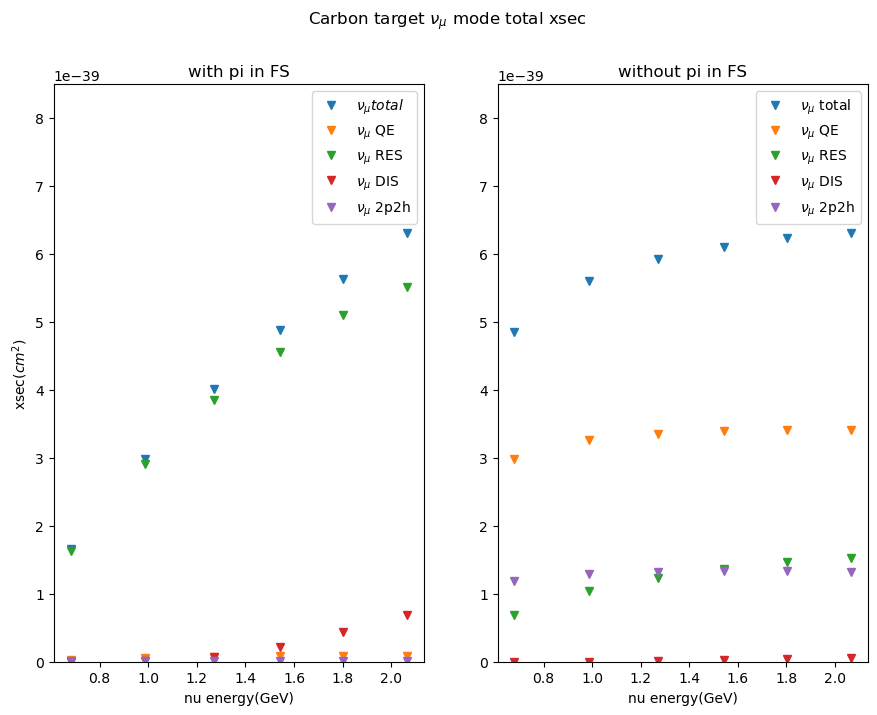

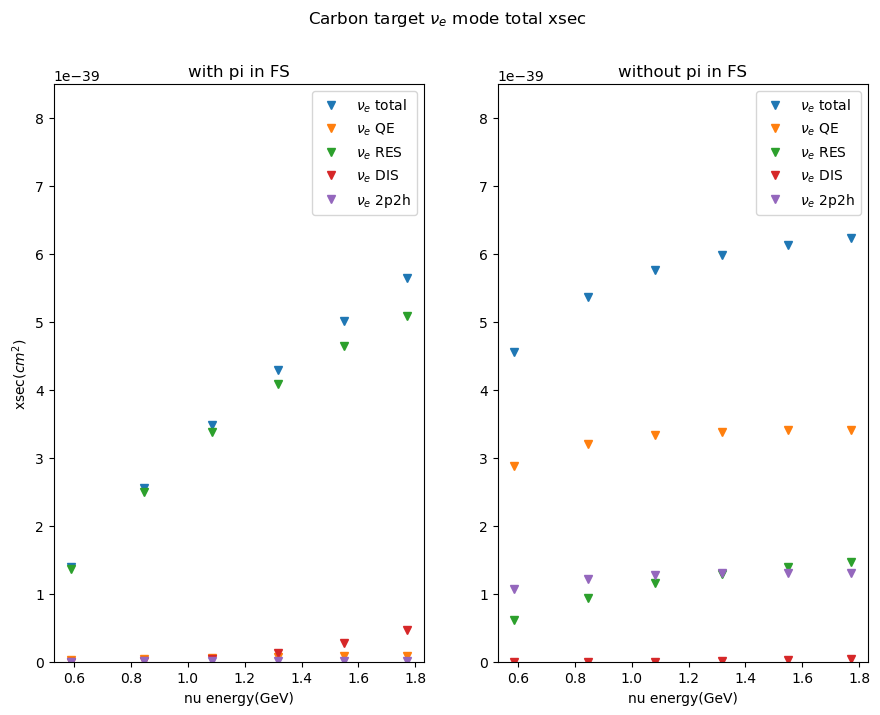

In [17]:
#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Carbon target ${\\nu}_{\mu}$ mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)


ax1.plot(musig_numu_E_lst, Carbon_nu_mu_outana7_xsec_lst+Carbon_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu} total$', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_nu_mu_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')
#ax3.plot(musig_numu_E_lst, Carbon_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')

#QE_xsec


ax1.plot(musig_numu_E_lst, Carbon_nu_mu_outana7_QE_xsec_lst+Carbon_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_nu_mu_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
#ax3.plot(musig_numu_E_lst, Carbon_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')

#RES_xsec

ax1.plot(musig_numu_E_lst, Carbon_nu_mu_outana7_RES_xsec_lst+Carbon_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_nu_mu_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
#ax3.plot(musig_numu_E_lst, Carbon_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')

#DIS_xsec

ax1.plot(musig_numu_E_lst, Carbon_nu_mu_outana7_DIS_xsec_lst+Carbon_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_nu_mu_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
#ax3.plot(musig_numu_E_lst, Carbon_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_numu_E_lst, Carbon_nu_mu_outana7_2p2h_xsec_lst+Carbon_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_nu_mu_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
#ax3.plot(musig_numu_E_lst, Carbon_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')


ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
ax1.set_ylim(0,8.5e-39)
ax2.legend()
ax2.set_ylim(0,8.5e-39)


plt.show()


#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Carbon target ${\\nu}_{e}$ mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)
ax1.plot(musig_nue_E_lst, Carbon_nu_e_outana7_xsec_lst+Carbon_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_nu_e_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
#ax3.plot(musig_nue_E_lst, Carbon_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')

#QE_xsec

ax1.plot(musig_nue_E_lst, Carbon_nu_e_outana7_QE_xsec_lst+Carbon_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_nu_e_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#ax3.plot(musig_nue_E_lst, Carbon_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#RES_xsec

ax1.plot(musig_nue_E_lst, Carbon_nu_e_outana7_RES_xsec_lst+Carbon_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_nu_e_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#ax3.plot(musig_nue_E_lst, Carbon_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#DIS_xsec

ax1.plot(musig_nue_E_lst, Carbon_nu_e_outana7_DIS_xsec_lst+Carbon_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_nu_e_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
#ax3.plot(musig_nue_E_lst, Carbon_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_nue_E_lst, Carbon_nu_e_outana7_2p2h_xsec_lst+Carbon_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_nu_e_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
#ax3.plot(musig_nue_E_lst, Carbon_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')

ax1.plot(musig_nue_E_lst, zero_line, linestyle='None')
ax2.plot(musig_nue_E_lst, zero_line, linestyle='None')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
ax1.set_ylim(0,8.5e-39)
ax2.legend()
ax2.set_ylim(0,8.5e-39)


plt.show()

In [22]:
musig_numu_E_lst = np.array([0.680172,0.987434,1.269619,1.541310,1.803612,2.064412])
musig_nue_E_lst = np.array([0.587738,0.846176,1.083320,1.317211,1.549514,1.769975])
zero_line = np.array([0,0,0,0,0,0])


Carbon_anti_nu_e_charged_pi_xsec_lst = np.array([9.5318e-41, 2.48227e-40, 4.22482e-40, 6.09944e-40, 8.03437e-40, 9.89275e-40]) 
Carbon_anti_nu_e_charged_pi_QE_xsec_lst = np.array([7.41543e-43, 2.76286e-42, 5.2261e-42, 7.84236e-42, 1.03898e-41, 1.2663e-41]) 
Carbon_anti_nu_e_charged_pi_RES_xsec_lst = np.array([9.44311e-41, 2.44533e-40, 4.12194e-40, 5.83634e-40, 7.48248e-40, 8.94472e-40]) 
Carbon_anti_nu_e_charged_pi_DIS_xsec_lst = np.array([7.0205e-46, 3.37008e-43, 3.91845e-42, 1.67593e-41, 4.25565e-41, 7.94295e-41]) 
Carbon_anti_nu_e_charged_pi_2p2h_xsec_lst = np.array([1.44713e-43, 5.94371e-43, 1.14345e-42, 1.70812e-42, 2.24288e-42, 2.71065e-42]) 

Carbon_anti_nu_e_outana7_xsec_lst =  np.array([2.6478e-41, 7.22603e-41, 1.24974e-40, 1.81633e-40, 2.39558e-40, 2.94379e-40])
Carbon_anti_nu_e_outana7_QE_xsec_lst = np.array([3.55532e-43, 1.30839e-42, 2.44372e-42, 3.62816e-42, 4.75604e-42, 5.7477e-42])
Carbon_anti_nu_e_outana7_RES_xsec_lst = np.array([2.60285e-41, 7.04639e-41, 1.20515e-40, 1.71654e-40, 2.20554e-40, 2.63754e-40])
Carbon_anti_nu_e_outana7_DIS_xsec_lst = np.array([2.95285e-46, 1.22627e-43, 1.32664e-42, 5.33354e-42, 1.29217e-41, 2.32808e-41])
Carbon_anti_nu_e_outana7_2p2h_xsec_lst = np.array([9.35865e-44, 3.65403e-43, 6.88547e-43, 1.01682e-42, 1.32655e-42, 1.59677e-42])

Carbon_anti_nu_e_outana9_xsec_lst =np.array([3.39302e-40, 5.66558e-40, 7.53432e-40, 9.12345e-40, 1.0492e-39, 1.16274e-39])
Carbon_anti_nu_e_outana9_QE_xsec_lst = np.array([1.54976e-40, 2.20268e-40, 2.67865e-40, 3.05142e-40, 3.35343e-40, 3.59516e-40])
Carbon_anti_nu_e_outana9_RES_xsec_lst = np.array([9.78446e-41, 1.99779e-40, 2.92127e-40, 3.74986e-40, 4.48415e-40, 5.10038e-40])
Carbon_anti_nu_e_outana9_DIS_xsec_lst = np.array([9.67721e-47, 3.78525e-44, 3.83232e-43, 1.46977e-42, 3.46693e-42, 6.15721e-42])
Carbon_anti_nu_e_outana9_2p2h_xsec_lst = np.array([8.64811e-41, 1.46473e-40, 1.93057e-40, 2.30747e-40, 2.61973e-40, 2.87025e-40])


Carbon_anti_nu_mu_charged_pi_xsec_lst = np.array([1.20501e-40, 3.188e-40, 5.39602e-40, 7.65255e-40, 9.87881e-40, 1.21068e-39]) 
Carbon_anti_nu_mu_charged_pi_QE_xsec_lst = np.array([1.20235e-42, 4.05302e-42, 7.25158e-42, 1.0294e-41, 1.30049e-41, 1.54677e-41]) 
Carbon_anti_nu_mu_charged_pi_RES_xsec_lst = np.array([1.19056e-40, 3.1309e-40, 5.21864e-40, 7.19869e-40, 8.97897e-40, 1.06017e-39]) 
Carbon_anti_nu_mu_charged_pi_DIS_xsec_lst = np.array([1.12657e-45, 7.75311e-43, 8.89909e-42, 3.28504e-41, 7.41624e-41, 1.31717e-40]) 
Carbon_anti_nu_mu_charged_pi_2p2h_xsec_lst = np.array([2.41618e-43, 8.81907e-43, 1.58744e-42, 2.24172e-42, 2.81641e-42, 3.32982e-42]) 

Carbon_anti_nu_mu_outana7_xsec_lst = np.array([3.38243e-41, 9.35629e-41, 1.60537e-40, 2.28499e-40, 2.9449e-40, 3.59233e-40])
Carbon_anti_nu_mu_outana7_QE_xsec_lst = np.array([5.81475e-43, 1.90887e-42, 3.31972e-42, 4.68994e-42, 5.91194e-42, 7.00717e-42])
Carbon_anti_nu_mu_outana7_RES_xsec_lst = np.array([3.30884e-41, 9.0837e-41, 1.53334e-40, 2.12291e-40, 2.64931e-40, 3.12629e-40])
Carbon_anti_nu_mu_outana7_DIS_xsec_lst = np.array([4.13677e-46, 2.76084e-43, 2.9304e-42, 1.0189e-41, 2.19894e-41, 3.76452e-41])
Carbon_anti_nu_mu_outana7_2p2h_xsec_lst = np.array([1.54022e-43, 5.40989e-43, 9.52631e-43, 1.32902e-42, 1.65805e-42, 1.95181e-42])

Carbon_anti_nu_mu_outana9_xsec_lst = np.array([4.00689e-40, 6.63028e-40, 8.6877e-40, 1.03593e-39, 1.1732e-39, 1.29095e-39])
Carbon_anti_nu_mu_outana9_QE_xsec_lst = np.array([1.76725e-40, 2.47912e-40, 2.96982e-40, 3.34125e-40, 3.63249e-40, 3.86983e-40])
Carbon_anti_nu_mu_outana9_RES_xsec_lst = np.array([1.1453e-40, 2.37e-40, 3.43219e-40, 4.33126e-40, 5.08215e-40, 5.73342e-40])
Carbon_anti_nu_mu_outana9_DIS_xsec_lst = np.array([1.73937e-46, 8.816e-44, 8.60878e-43, 2.85779e-42, 6.00914e-42, 1.01343e-41])
Carbon_anti_nu_mu_outana9_2p2h_xsec_lst = np.array([1.09434e-40, 1.78028e-40, 2.27709e-40, 2.65826e-40, 2.95722e-40, 3.2049e-40])

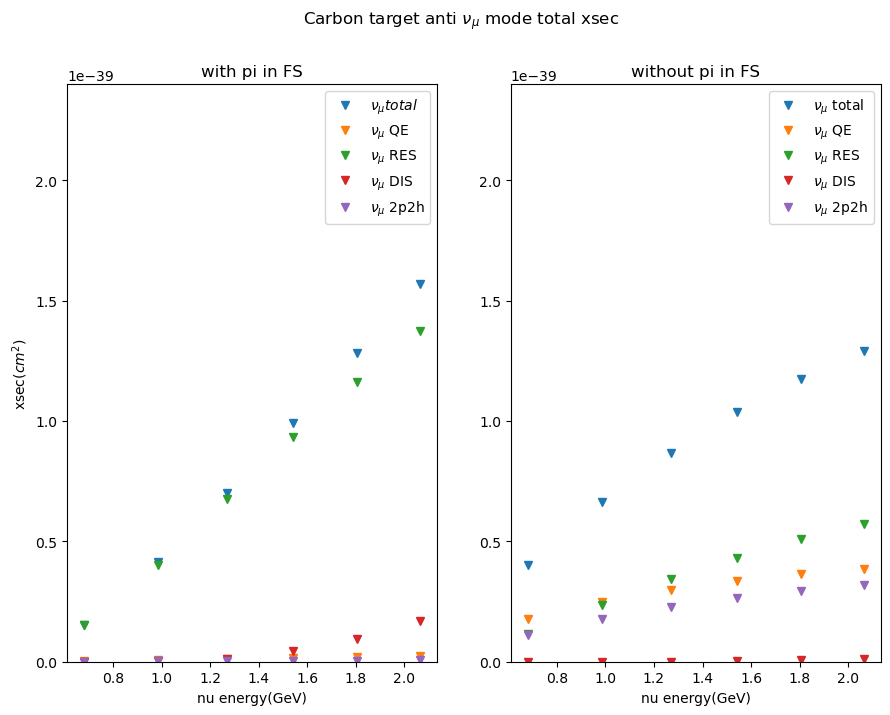

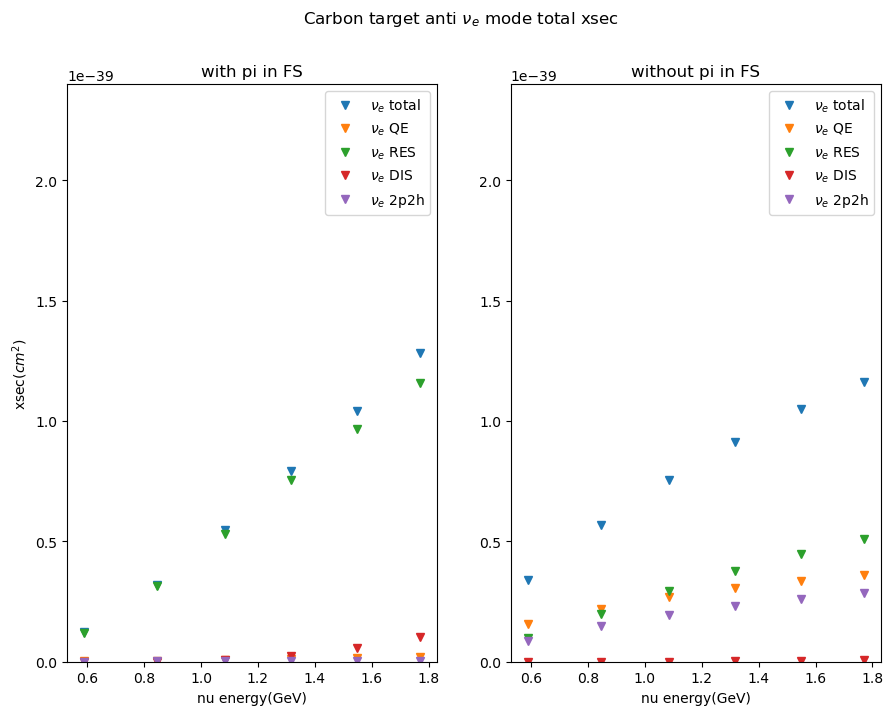

In [35]:
#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Carbon target anti ${\\nu}_{\mu}$ mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)


ax1.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana7_xsec_lst+Carbon_anti_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu} total$', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')
#ax3.plot(musig_numu_E_lst, Carbon_anti_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')

#QE_xsec


ax1.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana7_QE_xsec_lst+Carbon_anti_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
#ax3.plot(musig_numu_E_lst, Carbon_anti_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')

#RES_xsec

ax1.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana7_RES_xsec_lst+Carbon_anti_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
#ax3.plot(musig_numu_E_lst, Carbon_anti_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')

#DIS_xsec

ax1.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana7_DIS_xsec_lst+Carbon_anti_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
#ax3.plot(musig_numu_E_lst, Carbon_anti_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana7_2p2h_xsec_lst+Carbon_anti_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
#ax3.plot(musig_numu_E_lst, Carbon_anti_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')


ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
ax1.set_ylim(0,2.4e-39)
ax2.legend()
ax2.set_ylim(0,2.4e-39)


plt.show()


#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Carbon target anti ${\\nu}_{e}$ mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)
ax1.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana7_xsec_lst+Carbon_anti_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
#ax3.plot(musig_nue_E_lst, Carbon_anti_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')

#QE_xsec

ax1.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana7_QE_xsec_lst+Carbon_anti_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#ax3.plot(musig_nue_E_lst, Carbon_anti_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#RES_xsec

ax1.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana7_RES_xsec_lst+Carbon_anti_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#ax3.plot(musig_nue_E_lst, Carbon_anti_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#DIS_xsec

ax1.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana7_DIS_xsec_lst+Carbon_anti_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
#ax3.plot(musig_nue_E_lst, Carbon_anti_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana7_2p2h_xsec_lst+Carbon_anti_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
#ax3.plot(musig_nue_E_lst, Carbon_anti_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')

ax1.plot(musig_nue_E_lst, zero_line, linestyle='None')
ax2.plot(musig_nue_E_lst, zero_line, linestyle='None')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
ax1.set_ylim(0,2.4e-39)
ax2.legend()
ax2.set_ylim(0,2.4e-39)


plt.show()

In [25]:
musig_numu_E_lst = np.array([0.680172,0.987434,1.269619,1.541310,1.803612,2.064412])
musig_nue_E_lst = np.array([0.587738,0.846176,1.083320,1.317211,1.549514,1.769975])
zero_line = np.array([0,0,0,0,0,0])


Oxygen_nu_e_charged_pi_xsec_lst = np.array([9.91452e-40, 1.81168e-39, 2.47952e-39, 3.06046e-39, 3.58393e-39, 4.03932e-39]) 
Oxygen_nu_e_charged_pi_QE_xsec_lst =np.array([1.27602e-41, 2.86374e-41, 3.97595e-41, 4.73057e-41, 5.25769e-41, 5.60968e-41])
Oxygen_nu_e_charged_pi_RES_xsec_lst = np.array([9.76693e-40, 1.77468e-39, 2.40334e-39, 2.90632e-39, 3.31098e-39, 3.62313e-39]) 
Oxygen_nu_e_charged_pi_DIS_xsec_lst = np.array([8.9358e-45, 3.42307e-42, 2.9183e-41, 9.79689e-41, 2.10322e-40, 3.49235e-40]) 
Oxygen_nu_e_charged_pi_2p2h_xsec_lst = np.array([1.9902e-42, 4.94898e-42, 7.234e-42, 8.86887e-42, 1.00477e-41, 1.08583e-41]) 

Oxygen_nu_e_outana7_xsec_lst = np.array([3.25112e-40, 6.15937e-40, 8.59334e-40, 1.07211e-39, 1.26251e-39, 1.42597e-39]) 
Oxygen_nu_e_outana7_QE_xsec_lst = np.array([7.47751e-42, 1.65716e-41, 2.26375e-41, 2.65642e-41, 2.92891e-41, 3.11068e-41])
Oxygen_nu_e_outana7_RES_xsec_lst = np.array([3.16315e-40, 5.94837e-40, 8.20931e-40, 1.00357e-39, 1.15074e-39, 1.26413e-39])
Oxygen_nu_e_outana7_DIS_xsec_lst = np.array([3.97071e-45, 1.37755e-42, 1.12443e-41, 3.65039e-41, 7.63287e-41, 1.24123e-40])
Oxygen_nu_e_outana7_2p2h_xsec_lst = np.array([1.31533e-42, 3.15072e-42, 4.52135e-42, 5.47546e-42, 6.15251e-42, 6.61651e-42])

Oxygen_nu_e_outana9_xsec_lst = np.array([4.62069e-39, 5.4901e-39, 5.91918e-39, 6.17295e-39, 6.33664e-39, 6.45841e-39]) 
Oxygen_nu_e_outana9_QE_xsec_lst = np.array([2.86039e-39, 3.18583e-39, 3.30766e-39, 3.35958e-39, 3.37903e-39, 3.39064e-39])
Oxygen_nu_e_outana9_RES_xsec_lst = np.array([6.99486e-40, 1.09086e-39, 1.3396e-39, 1.51009e-39, 1.63405e-39, 1.72428e-39])
Oxygen_nu_e_outana9_DIS_xsec_lst = np.array([1.72785e-45, 5.21244e-43, 4.08001e-42, 1.29449e-41, 2.66119e-41, 4.26308e-41])
Oxygen_nu_e_outana9_2p2h_xsec_lst = np.array([1.06081e-39, 1.21289e-39, 1.26783e-39, 1.29034e-39, 1.29696e-39, 1.30086e-39])


Oxygen_nu_mu_charged_pi_xsec_lst = np.array([1.18202e-39, 2.12049e-39, 2.85816e-39, 3.48556e-39, 4.0328e-39, 4.53367e-39]) 
Oxygen_nu_mu_charged_pi_QE_xsec_lst = np.array([1.76326e-41, 3.57501e-41, 4.65275e-41, 5.31835e-41, 5.73889e-41, 6.02845e-41]) 
Oxygen_nu_mu_charged_pi_RES_xsec_lst = np.array([1.16139e-39, 2.07215e-39, 2.74826e-39, 3.25593e-39, 3.6368e-39, 3.93727e-39]) 
Oxygen_nu_mu_charged_pi_DIS_xsec_lst = np.array([8.53933e-45, 6.04336e-42, 5.45123e-41, 1.6611e-40, 3.2731e-40, 5.24152e-40]) 
Oxygen_nu_mu_charged_pi_2p2h_xsec_lst = np.array([2.98523e-42, 6.54617e-42, 8.86604e-42, 1.03429e-41, 1.1295e-41, 1.19686e-41])

Oxygen_nu_mu_outana7_xsec_lst = np.array([3.9055e-40, 7.26611e-40, 9.97047e-40, 1.22633e-39, 1.42371e-39, 1.60108e-39]) 
Oxygen_nu_mu_outana7_QE_xsec_lst = np.array([1.06438e-41, 2.05345e-41, 2.61068e-41, 2.94571e-41, 3.15994e-41, 3.30515e-41])
Oxygen_nu_mu_outana7_RES_xsec_lst = np.array([3.77927e-40, 6.99477e-40, 9.44512e-40, 1.12907e-39, 1.26745e-39, 1.37649e-39])
Oxygen_nu_mu_outana7_DIS_xsec_lst = np.array([3.71964e-45, 2.45722e-42, 2.09347e-41, 6.14683e-41, 1.1779e-40, 1.84296e-40])
Oxygen_nu_mu_outana7_2p2h_xsec_lst = np.array([1.97528e-42, 4.14172e-42, 5.49358e-42, 6.33476e-42, 6.86916e-42, 7.24477e-42])

Oxygen_nu_mu_outana9_xsec_lst = np.array([4.91238e-39, 5.71957e-39, 6.08517e-39, 6.29851e-39, 6.44383e-39, 6.5414e-39]) 
Oxygen_nu_mu_outana9_QE_xsec_lst = np.array([2.94824e-39, 3.23306e-39, 3.3232e-39, 3.35709e-39, 3.37275e-39, 3.37171e-39])
Oxygen_nu_mu_outana9_RES_xsec_lst = np.array([7.84977e-40, 1.19691e-39, 1.43885e-39, 1.59822e-39, 1.7082e-39, 1.79027e-39])
Oxygen_nu_mu_outana9_DIS_xsec_lst = np.array([1.59671e-45, 9.36258e-43, 7.69343e-42, 2.21036e-41, 4.15102e-41, 6.3638e-41])
Oxygen_nu_mu_outana9_2p2h_xsec_lst = np.array([1.17916e-39, 1.28866e-39, 1.31543e-39, 1.3211e-39, 1.32138e-39, 1.31579e-39])

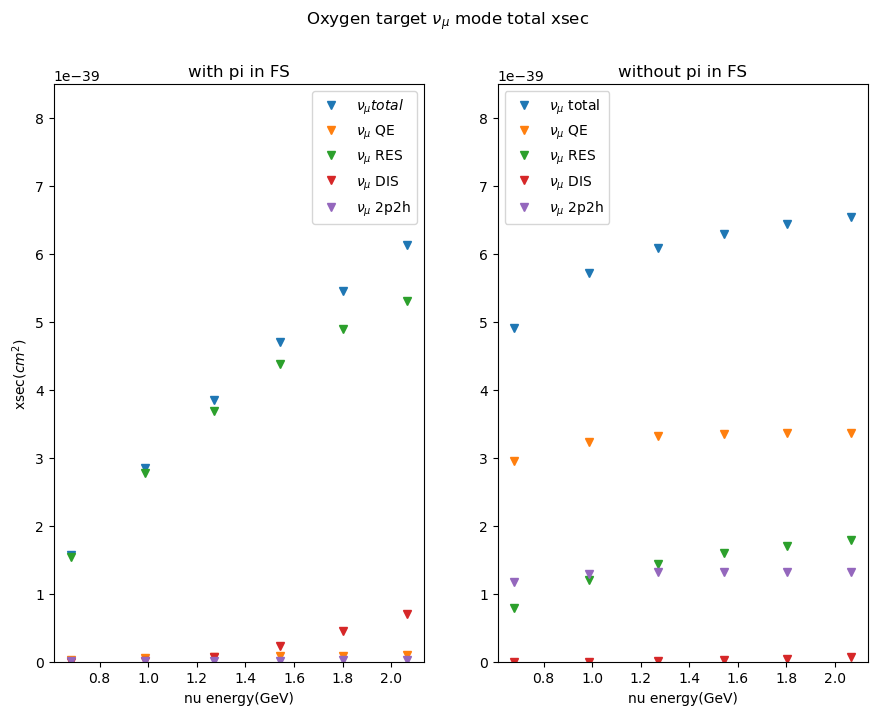

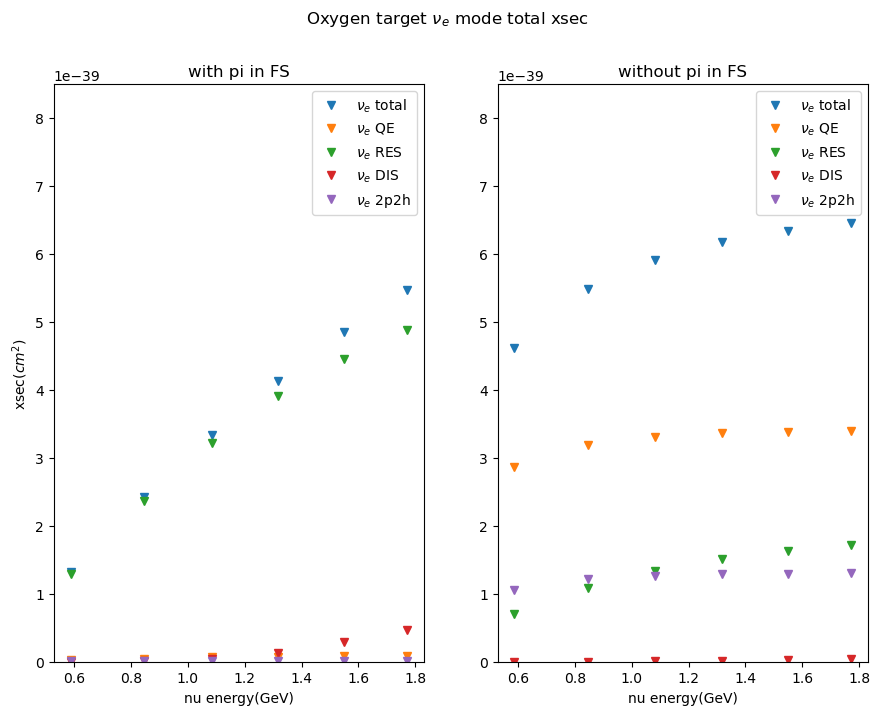

In [36]:
#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Oxygen target ${\\nu}_{\mu}$ mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)


ax1.plot(musig_numu_E_lst, Oxygen_nu_mu_outana7_xsec_lst+Oxygen_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu} total$', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_nu_mu_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')

#QE_xsec


ax1.plot(musig_numu_E_lst, Oxygen_nu_mu_outana7_QE_xsec_lst+Oxygen_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_nu_mu_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')

#RES_xsec

ax1.plot(musig_numu_E_lst, Oxygen_nu_mu_outana7_RES_xsec_lst+Oxygen_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_nu_mu_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')

#DIS_xsec

ax1.plot(musig_numu_E_lst, Oxygen_nu_mu_outana7_DIS_xsec_lst+Oxygen_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_nu_mu_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_numu_E_lst, Oxygen_nu_mu_outana7_2p2h_xsec_lst+Oxygen_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_nu_mu_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')


ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
ax1.set_ylim(0,8.5e-39)
ax2.legend()
ax2.set_ylim(0,8.5e-39)


plt.show()


#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Oxygen target ${\\nu}_{e}$ mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)
ax1.plot(musig_nue_E_lst, Oxygen_nu_e_outana7_xsec_lst+Oxygen_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_nu_e_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')

#QE_xsec

ax1.plot(musig_nue_E_lst, Oxygen_nu_e_outana7_QE_xsec_lst+Oxygen_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_nu_e_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#RES_xsec

ax1.plot(musig_nue_E_lst, Oxygen_nu_e_outana7_RES_xsec_lst+Oxygen_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_nu_e_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#DIS_xsec

ax1.plot(musig_nue_E_lst, Oxygen_nu_e_outana7_DIS_xsec_lst+Oxygen_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_nu_e_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_nue_E_lst, Oxygen_nu_e_outana7_2p2h_xsec_lst+Oxygen_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_nu_e_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')

ax1.plot(musig_nue_E_lst, zero_line, linestyle='None')
ax2.plot(musig_nue_E_lst, zero_line, linestyle='None')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
ax1.set_ylim(0,8.5e-39)
ax2.legend()
ax2.set_ylim(0,8.5e-39)


plt.show()

In [29]:
musig_numu_E_lst = np.array([0.680172,0.987434,1.269619,1.541310,1.803612,2.064412])
musig_nue_E_lst = np.array([0.587738,0.846176,1.083320,1.317211,1.549514,1.769975])
zero_line = np.array([0,0,0,0,0,0])


Oxygen_anti_nu_e_charged_pi_xsec_lst = np.array([9.31436e-41, 2.44015e-40, 4.17398e-40, 6.05495e-40, 8.01142e-40, 9.90161e-40]) 
Oxygen_anti_nu_e_charged_pi_QE_xsec_lst = np.array([7.8487e-43, 2.96151e-42, 5.53718e-42, 8.19142e-42, 1.07736e-41, 1.30676e-41]) 
Oxygen_anti_nu_e_charged_pi_RES_xsec_lst = np.array([9.22011e-41, 2.40048e-40, 4.06419e-40, 5.77454e-40, 7.42252e-40, 8.88976e-40]) 
Oxygen_anti_nu_e_charged_pi_DIS_xsec_lst = np.array([7.07612e-46, 3.59113e-43, 4.19644e-42, 1.79897e-41, 4.56761e-41, 8.51687e-41]) 
Oxygen_anti_nu_e_charged_pi_2p2h_xsec_lst = np.array([1.56946e-43, 6.46395e-43, 1.24545e-42, 1.85975e-42, 2.44088e-42, 2.94928e-42]) 

Oxygen_anti_nu_e_outana7_xsec_lst = np.array([2.71506e-41, 7.47502e-41, 1.30289e-40, 1.90537e-40, 2.52555e-40, 3.11561e-40]) 
Oxygen_anti_nu_e_outana7_QE_xsec_lst = np.array([4.04531e-43, 1.44919e-42, 2.71089e-42, 3.99978e-42, 5.23469e-42, 6.32998e-42]) 
Oxygen_anti_nu_e_outana7_RES_xsec_lst = np.array([2.66456e-41, 7.27707e-41, 1.25349e-40, 1.79431e-40, 2.31305e-40, 2.77225e-40]) 
Oxygen_anti_nu_e_outana7_DIS_xsec_lst = np.array([3.37492e-46, 1.35431e-43, 1.48348e-42, 6.00438e-42, 1.45785e-41, 2.62767e-41])
Oxygen_anti_nu_e_outana7_2p2h_xsec_lst = np.array([1.001e-43, 3.94853e-43, 7.45816e-43, 1.10143e-42, 1.43679e-42, 1.72936e-42]) 

Oxygen_anti_nu_e_outana9_xsec_lst = np.array([3.83258e-40, 6.45284e-40, 8.62682e-40, 1.04893e-39, 1.21e-39, 1.34388e-39]) 
Oxygen_anti_nu_e_outana9_QE_xsec_lst = np.array([1.76804e-40, 2.51797e-40, 3.06285e-40, 3.49083e-40, 3.838e-40, 4.1149e-40]) 
Oxygen_anti_nu_e_outana9_RES_xsec_lst = np.array([1.1643e-40, 2.40714e-40, 3.54451e-40, 4.57034e-40, 5.4812e-40, 6.24652e-40]) 
Oxygen_anti_nu_e_outana9_DIS_xsec_lst = np.array([1.20829e-46, 5.18349e-44, 5.07415e-43, 1.9167e-42, 4.47377e-42, 7.88396e-42])
Oxygen_anti_nu_e_outana9_2p2h_xsec_lst = np.array([9.00246e-41, 1.52721e-40, 2.01439e-40, 2.40896e-40, 2.73604e-40, 2.99854e-40])


Oxygen_anti_nu_mu_charged_pi_xsec_lst = np.array([1.17821e-40, 3.13992e-40, 5.3485e-40, 7.62613e-40, 9.88995e-40, 1.2168e-39]) 
Oxygen_anti_nu_mu_charged_pi_QE_xsec_lst = np.array([1.24201e-42, 4.12435e-42, 7.40272e-42, 1.0508e-41, 1.33184e-41, 1.58869e-41]) 
Oxygen_anti_nu_mu_charged_pi_RES_xsec_lst = np.array([1.16314e-40, 3.08077e-40, 5.16183e-40, 7.14429e-40, 8.93109e-40, 1.05624e-39]) 
Oxygen_anti_nu_mu_charged_pi_DIS_xsec_lst = np.array([1.23713e-45, 8.26968e-43, 9.5342e-42, 3.52399e-41, 7.95112e-41, 1.41058e-40]) 
Oxygen_anti_nu_mu_charged_pi_2p2h_xsec_lst = np.array([2.64474e-43, 9.64461e-43, 1.72996e-42, 2.43593e-42, 3.05663e-42, 3.61345e-42]) 

Oxygen_anti_nu_mu_outana7_xsec_lst = np.array([3.48292e-41, 9.72724e-41, 1.681e-40, 2.40648e-40, 3.11611e-40, 3.81605e-40]) 
Oxygen_anti_nu_mu_outana7_QE_xsec_lst = np.array([6.09298e-43, 2.07504e-42, 3.69723e-42, 5.20027e-42, 6.52056e-42, 7.72003e-42]) 
Oxygen_anti_nu_mu_outana7_RES_xsec_lst = np.array([3.40543e-41, 9.43085e-41, 1.6008e-40, 2.22501e-40, 2.78431e-40, 3.292e-40]) 
Oxygen_anti_nu_mu_outana7_DIS_xsec_lst = np.array([4.88566e-46, 3.05752e-43, 3.29199e-42, 1.15092e-41, 2.48678e-41, 4.25764e-41]) 
Oxygen_anti_nu_mu_outana7_2p2h_xsec_lst = np.array([1.6518e-43, 5.83184e-43, 1.03067e-42, 1.43746e-42, 1.79195e-42, 2.10854e-42]) 

Oxygen_anti_nu_mu_outana9_xsec_lst = np.array([4.53289e-40, 7.57865e-40, 9.99376e-40, 1.19647e-39, 1.35832e-39, 1.49741e-39]) 
Oxygen_anti_nu_mu_outana9_QE_xsec_lst = np.array([2.0237e-40, 2.85171e-40, 3.42533e-40, 3.857e-40, 4.1905e-40, 4.46035e-40]) 
Oxygen_anti_nu_mu_outana9_RES_xsec_lst = np.array([1.3687e-40, 2.86786e-40, 4.17965e-40, 5.29407e-40, 6.22608e-40, 7.03566e-40]) 
Oxygen_anti_nu_mu_outana9_DIS_xsec_lst = np.array([1.91086e-46, 1.18464e-43, 1.13424e-42, 3.70496e-42, 7.71119e-42, 1.29194e-41]) 
Oxygen_anti_nu_mu_outana9_2p2h_xsec_lst = np.array([1.14049e-40, 1.8579e-40, 2.37743e-40, 2.77654e-40, 3.08955e-40, 3.34888e-40]) 

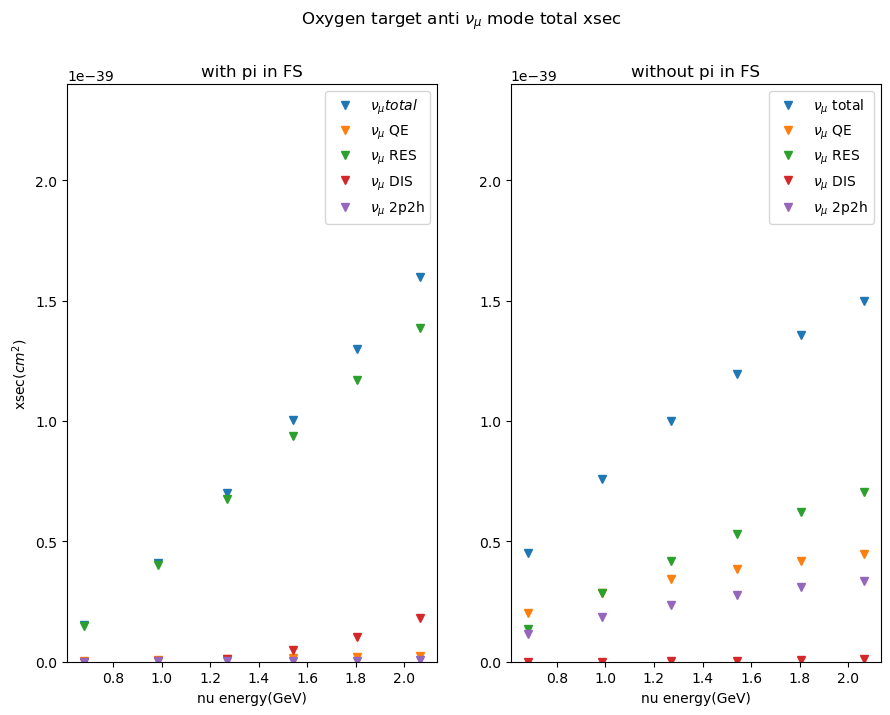

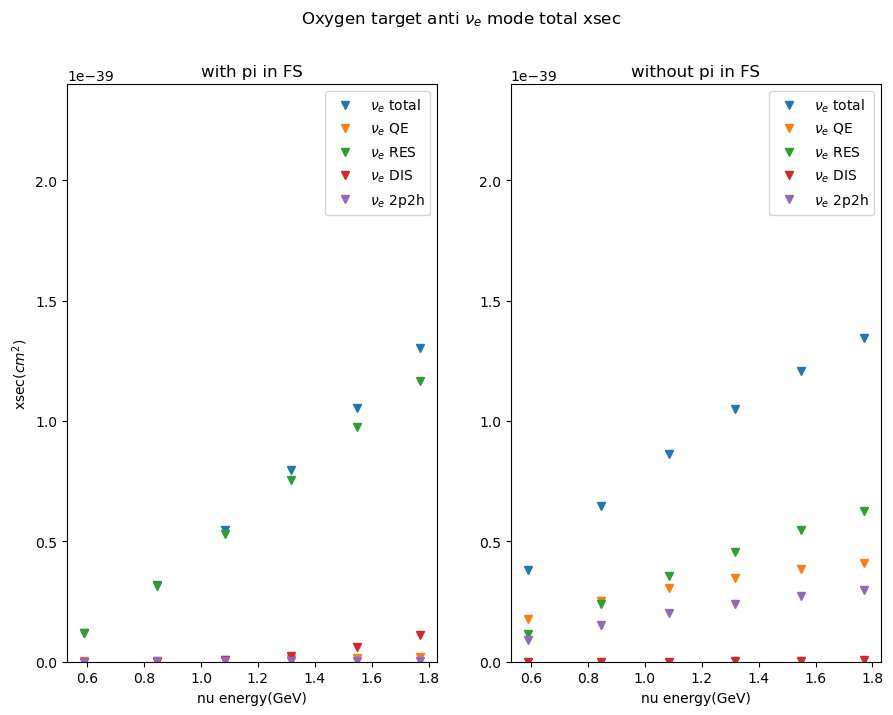

In [37]:
#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Oxygen target anti ${\\nu}_{\mu}$ mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)


ax1.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana7_xsec_lst+Oxygen_anti_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu} total$', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')

#QE_xsec


ax1.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana7_QE_xsec_lst+Oxygen_anti_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')

#RES_xsec

ax1.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana7_RES_xsec_lst+Oxygen_anti_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')

#DIS_xsec

ax1.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana7_DIS_xsec_lst+Oxygen_anti_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana7_2p2h_xsec_lst+Oxygen_anti_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')


ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
ax1.set_ylim(0,2.4e-39)
ax2.legend()
ax2.set_ylim(0,2.4e-39)


plt.show()


#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Oxygen target anti ${\\nu}_{e}$ mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)
ax1.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana7_xsec_lst+Oxygen_anti_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_anti_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')

#QE_xsec

ax1.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana7_QE_xsec_lst+Oxygen_anti_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_anti_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#RES_xsec

ax1.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana7_RES_xsec_lst+Oxygen_anti_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_anti_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#DIS_xsec

ax1.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana7_DIS_xsec_lst+Oxygen_anti_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_anti_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana7_2p2h_xsec_lst+Oxygen_anti_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_anti_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')

ax1.plot(musig_nue_E_lst, zero_line, linestyle='None')
ax2.plot(musig_nue_E_lst, zero_line, linestyle='None')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
ax1.set_ylim(0,2.4e-39)
ax2.legend()
ax2.set_ylim(0,2.4e-39)


plt.show()

In [31]:
musig_numu_E_lst = np.array([0.680172,0.987434,1.269619,1.541310,1.803612,2.064412])
musig_nue_E_lst = np.array([0.587738,0.846176,1.083320,1.317211,1.549514,1.769975])
zero_line = np.array([0,0,0,0,0,0])


Argon_nu_e_charged_pi_xsec_lst = np.array([7.12527e-40, 1.34329e-39, 1.88566e-39, 2.38082e-39, 2.84417e-39, 3.25935e-39]) 
Argon_nu_e_charged_pi_QE_xsec_lst =np.array([1.38209e-41, 3.10782e-41, 4.336e-41, 5.1741e-41, 5.76751e-41, 6.17212e-41])
Argon_nu_e_charged_pi_RES_xsec_lst = np.array([6.96489e-40, 1.30331e-39, 1.80476e-39, 2.21918e-39, 2.55901e-39, 2.82443e-39]) 
Argon_nu_e_charged_pi_DIS_xsec_lst = np.array([8.8326e-45, 3.40104e-42, 2.94829e-41, 9.99951e-41, 2.16242e-40, 3.61036e-40]) 
Argon_nu_e_charged_pi_2p2h_xsec_lst = np.array([2.208e-42, 5.49871e-42, 8.05951e-42, 9.9032e-42, 1.12406e-41, 1.21649e-41]) 

Argon_nu_e_outana7_xsec_lst = np.array([2.70543e-40, 5.29346e-40, 7.57316e-40, 9.6529e-40, 1.15712e-39, 1.32559e-39]) 
Argon_nu_e_outana7_QE_xsec_lst = np.array([9.36812e-42, 2.01689e-41, 2.75642e-41, 3.24294e-41, 3.57669e-41, 3.80259e-41])
Argon_nu_e_outana7_RES_xsec_lst = np.array([2.59638e-40, 5.03979e-40, 7.11762e-40, 8.84809e-40, 1.02662e-39, 1.13704e-39])
Argon_nu_e_outana7_DIS_xsec_lst = np.array([4.16523e-45, 1.53936e-42, 1.27426e-41, 4.16952e-41, 8.75846e-41, 1.42845e-40])
Argon_nu_e_outana7_2p2h_xsec_lst = np.array([1.53295e-42, 3.6593e-42, 5.24704e-42, 6.35655e-42, 7.14686e-42, 7.68619e-42])

Argon_nu_e_outana9_xsec_lst = np.array([5.00072e-39, 6.11971e-39, 6.7299e-39, 7.12099e-39, 7.39139e-39, 7.59504e-39]) 
Argon_nu_e_outana9_QE_xsec_lst = np.array([2.98371e-39, 3.34093e-39, 3.48075e-39, 3.54347e-39, 3.56873e-39, 3.5842e-39])
Argon_nu_e_outana9_RES_xsec_lst = np.array([9.59937e-40, 1.56208e-39, 1.96682e-39, 2.25383e-39, 2.46663e-39, 2.62261e-39])
Argon_nu_e_outana9_DIS_xsec_lst = np.array([4.82311e-45, 1.23897e-42, 8.76443e-42, 2.58428e-41, 5.0483e-41, 7.81017e-41])
Argon_nu_e_outana9_2p2h_xsec_lst = np.array([1.05707e-39, 1.21546e-39, 1.27356e-39, 1.29784e-39, 1.30554e-39, 1.31013e-39])


Argon_nu_mu_charged_pi_xsec_lst = np.array([8.56065e-40, 1.58976e-39, 2.20462e-39, 2.75403e-39, 3.25169e-39, 3.72019e-39]) 
Argon_nu_mu_charged_pi_QE_xsec_lst = np.array([1.90113e-41, 3.85195e-41, 5.04989e-41, 5.81002e-41, 6.29995e-41, 6.64601e-41]) 
Argon_nu_mu_charged_pi_RES_xsec_lst = np.array([8.33716e-40, 1.53789e-39, 2.08895e-39, 2.51438e-39, 2.83889e-39, 3.09735e-39]) 
Argon_nu_mu_charged_pi_DIS_xsec_lst = np.array([8.26669e-45, 6.05771e-42, 5.52819e-41, 1.69995e-40, 3.37169e-40, 5.42991e-40]) 
Argon_nu_mu_charged_pi_2p2h_xsec_lst = np.array([3.32943e-42, 7.29678e-42, 9.89379e-42, 1.15506e-41, 1.26261e-41, 1.33891e-41])

Argon_nu_mu_outana7_xsec_lst = np.array([3.27857e-40, 6.32586e-40, 8.91737e-40, 1.12075e-39, 1.32358e-39, 1.5097e-39]) 
Argon_nu_mu_outana7_QE_xsec_lst = np.array([1.31527e-41, 2.55377e-41, 3.25404e-41, 3.67728e-41, 3.93569e-41, 4.12054e-41])
Argon_nu_mu_outana7_RES_xsec_lst = np.array([3.12407e-40, 5.99543e-40, 8.29179e-40, 1.00658e-39, 1.14143e-39, 1.24849e-39])
Argon_nu_mu_outana7_DIS_xsec_lst = np.array([4.10919e-45, 2.71943e-42, 2.36598e-41, 7.0056e-41, 1.34823e-40, 2.11599e-40])
Argon_nu_mu_outana7_2p2h_xsec_lst = np.array([2.293e-42, 4.78625e-42, 6.35764e-42, 7.34148e-42, 7.97133e-42, 8.41366e-42])

Argon_nu_mu_outana9_xsec_lst = np.array([5.37583e-39, 6.45289e-39, 6.99913e-39, 7.34271e-39, 7.5858e-39, 7.76148e-39]) 
Argon_nu_mu_outana9_QE_xsec_lst = np.array([3.10352e-39, 3.41531e-39, 3.51608e-39, 3.55445e-39, 3.57296e-39, 3.57396e-39])
Argon_nu_mu_outana9_RES_xsec_lst = np.array([1.09287e-39, 1.74149e-39, 2.14431e-39, 2.41604e-39, 2.60593e-39, 2.74878e-39])
Argon_nu_mu_outana9_DIS_xsec_lst = np.array([4.3208e-45, 2.16594e-42, 1.58459e-41, 4.24658e-41, 7.62511e-41, 1.13216e-40])
Argon_nu_mu_outana9_2p2h_xsec_lst = np.array([1.17944e-39, 1.29392e-39, 1.32289e-39, 1.32974e-39, 1.33066e-39, 1.32553e-39])

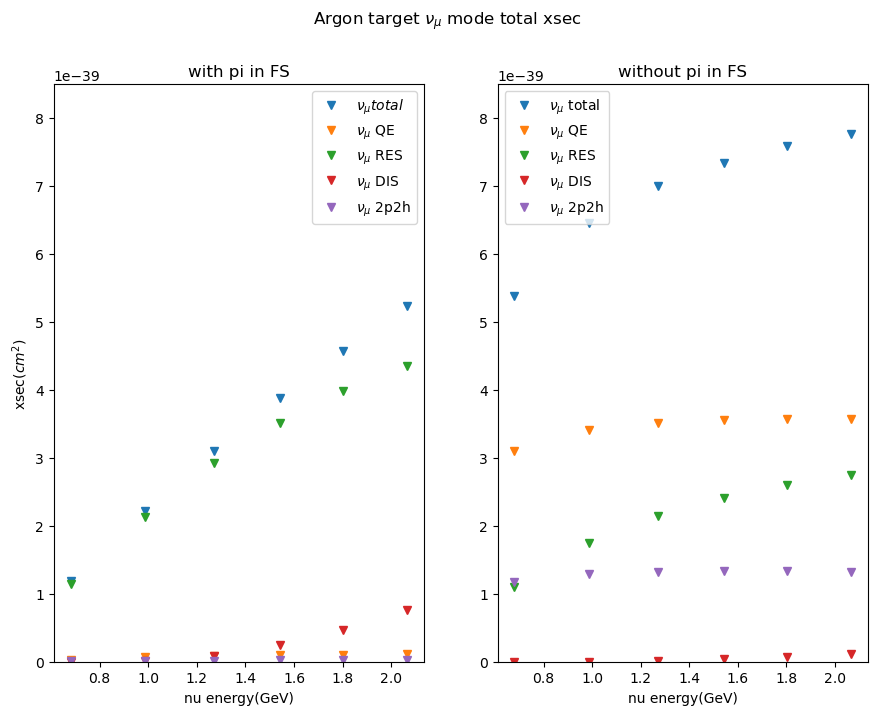

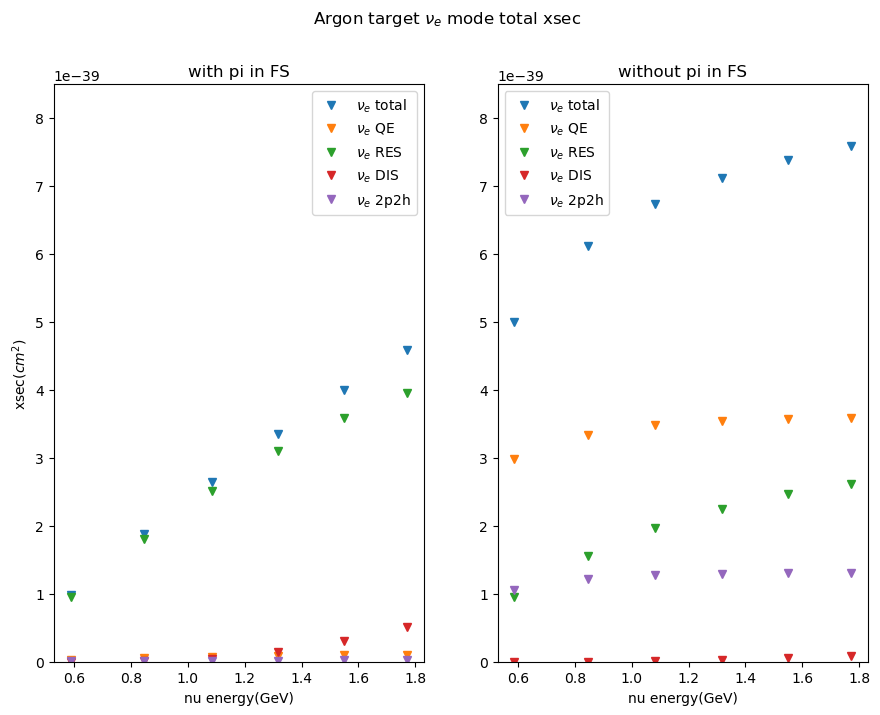

In [38]:
#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Argon target ${\\nu}_{\mu}$ mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)


ax1.plot(musig_numu_E_lst, Argon_nu_mu_outana7_xsec_lst+Argon_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu} total$', marker='v')
ax2.plot(musig_numu_E_lst, Argon_nu_mu_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')
#ax3.plot(musig_numu_E_lst, Argon_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')

#QE_xsec


ax1.plot(musig_numu_E_lst, Argon_nu_mu_outana7_QE_xsec_lst+Argon_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
ax2.plot(musig_numu_E_lst, Argon_nu_mu_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
#ax3.plot(musig_numu_E_lst, Argon_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')

#RES_xsec

ax1.plot(musig_numu_E_lst, Argon_nu_mu_outana7_RES_xsec_lst+Argon_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
ax2.plot(musig_numu_E_lst, Argon_nu_mu_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
#ax3.plot(musig_numu_E_lst, Argon_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')

#DIS_xsec

ax1.plot(musig_numu_E_lst, Argon_nu_mu_outana7_DIS_xsec_lst+Argon_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
ax2.plot(musig_numu_E_lst, Argon_nu_mu_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
#ax3.plot(musig_numu_E_lst, Argon_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_numu_E_lst, Argon_nu_mu_outana7_2p2h_xsec_lst+Argon_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
ax2.plot(musig_numu_E_lst, Argon_nu_mu_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
#ax3.plot(musig_numu_E_lst, Argon_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')


ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
ax1.set_ylim(0,8.5e-39)
ax2.legend()
ax2.set_ylim(0,8.5e-39)


plt.show()


#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Argon target ${\\nu}_{e}$ mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)
ax1.plot(musig_nue_E_lst, Argon_nu_e_outana7_xsec_lst+Argon_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
ax2.plot(musig_nue_E_lst, Argon_nu_e_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
#ax3.plot(musig_nue_E_lst, Argon_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')

#QE_xsec

ax1.plot(musig_nue_E_lst, Argon_nu_e_outana7_QE_xsec_lst+Argon_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax2.plot(musig_nue_E_lst, Argon_nu_e_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#ax3.plot(musig_nue_E_lst, Argon_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#RES_xsec

ax1.plot(musig_nue_E_lst, Argon_nu_e_outana7_RES_xsec_lst+Argon_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax2.plot(musig_nue_E_lst, Argon_nu_e_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#ax3.plot(musig_nue_E_lst, Argon_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#DIS_xsec

ax1.plot(musig_nue_E_lst, Argon_nu_e_outana7_DIS_xsec_lst+Argon_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax2.plot(musig_nue_E_lst, Argon_nu_e_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
#ax3.plot(musig_nue_E_lst, Argon_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_nue_E_lst, Argon_nu_e_outana7_2p2h_xsec_lst+Argon_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax2.plot(musig_nue_E_lst, Argon_nu_e_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
#ax3.plot(musig_nue_E_lst, Argon_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')

ax1.plot(musig_nue_E_lst, zero_line, linestyle='None')
ax2.plot(musig_nue_E_lst, zero_line, linestyle='None')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
ax1.set_ylim(0,8.5e-39)
ax2.legend()
ax2.set_ylim(0,8.5e-39)


plt.show()

In [33]:
musig_numu_E_lst = np.array([0.680172,0.987434,1.269619,1.541310,1.803612,2.064412])
musig_nue_E_lst = np.array([0.587738,0.846176,1.083320,1.317211,1.549514,1.769975])
zero_line = np.array([0,0,0,0,0,0])


Argon_anti_nu_e_charged_pi_xsec_lst = np.array([7.98233e-41, 2.1187e-40, 3.69056e-40, 5.46001e-40, 7.36142e-40, 9.24736e-40]) 
Argon_anti_nu_e_charged_pi_QE_xsec_lst = np.array([7.92977e-43, 2.89176e-42, 5.45282e-42, 8.12647e-42, 1.07318e-41, 1.30668e-41]) 
Argon_anti_nu_e_charged_pi_RES_xsec_lst = np.array([7.88622e-41, 2.07906e-40, 3.57518e-40, 5.14939e-40, 6.68997e-40, 8.07723e-40]) 
Argon_anti_nu_e_charged_pi_DIS_xsec_lst = np.array([7.70774e-46, 3.91056e-43, 4.77193e-42, 2.09713e-41, 5.38301e-41, 1.00821e-40]) 
Argon_anti_nu_e_charged_pi_2p2h_xsec_lst = np.array([1.6739e-43, 6.81328e-43, 1.3125e-42, 1.96403e-42, 2.58308e-42, 3.12594e-42]) 

Argon_anti_nu_e_outana7_xsec_lst = np.array([2.24153e-41, 6.40086e-41, 1.15103e-40, 1.73336e-40, 2.35798e-40, 2.9717e-40]) 
Argon_anti_nu_e_outana7_QE_xsec_lst = np.array([4.01382e-43, 1.39357e-42, 2.58304e-42, 3.84195e-42, 5.056e-42, 6.13357e-42]) 
Argon_anti_nu_e_outana7_RES_xsec_lst = np.array([2.19171e-41, 6.20773e-41, 1.09974e-40, 1.60777e-40, 2.10469e-40, 2.55064e-40]) 
Argon_anti_nu_e_outana7_DIS_xsec_lst = np.array([3.32908e-46, 1.57318e-43, 1.82565e-42, 7.64929e-42, 1.88797e-41, 3.42945e-41])
Argon_anti_nu_e_outana7_2p2h_xsec_lst = np.array([9.64576e-44, 3.80394e-43, 7.20559e-43, 1.06727e-42, 1.39341e-42, 1.67776e-42]) 

Argon_anti_nu_e_outana9_xsec_lst = np.array([4.53881e-40, 8.02292e-40, 1.10541e-39, 1.37326e-39, 1.60999e-39, 1.8097e-39]) 
Argon_anti_nu_e_outana9_QE_xsec_lst = np.array([1.95209e-40, 2.82392e-40, 3.46901e-40, 3.97837e-40, 4.39483e-40, 4.72951e-40]) 
Argon_anti_nu_e_outana9_RES_xsec_lst = np.array([1.77028e-40, 3.7909e-40, 5.70435e-40, 7.46695e-40, 9.05177e-40, 1.03943e-39]) 
Argon_anti_nu_e_outana9_DIS_xsec_lst = np.array([4.2332e-46, 1.3002e-43, 1.19843e-42, 4.31756e-42, 9.7043e-42, 1.66101e-41])
Argon_anti_nu_e_outana9_2p2h_xsec_lst = np.array([8.16443e-41, 1.40679e-40, 1.86871e-40, 2.24408e-40, 2.55623e-40, 2.80709e-40])


Argon_anti_nu_mu_charged_pi_xsec_lst = np.array([1.01526e-40, 2.75055e-40, 4.78609e-40, 6.97449e-40, 9.22514e-40, 1.1547e-39]) 
Argon_anti_nu_mu_charged_pi_QE_xsec_lst = np.array([1.25379e-42, 4.19551e-42, 7.4149e-42, 1.05502e-41, 1.34162e-41, 1.60543e-41]) 
Argon_anti_nu_mu_charged_pi_RES_xsec_lst = np.array([9.99911e-41, 2.68932e-40, 4.58416e-40, 6.42996e-40, 8.11878e-40, 9.6761e-40]) 
Argon_anti_nu_mu_charged_pi_DIS_xsec_lst = np.array([1.25036e-45, 9.07175e-43, 1.09457e-41, 4.13138e-41, 9.39679e-41, 1.67188e-40]) 
Argon_anti_nu_mu_charged_pi_2p2h_xsec_lst = np.array([2.80228e-43, 1.01966e-42, 1.83262e-42, 2.58868e-42, 3.25197e-42, 3.8453e-42]) 

Argon_anti_nu_mu_outana7_xsec_lst = np.array([2.89071e-41, 8.43256e-41, 1.51136e-40, 2.23304e-40, 2.96883e-40, 3.71591e-40]) 
Argon_anti_nu_mu_outana7_QE_xsec_lst = np.array([6.16712e-43, 1.99648e-42, 3.47718e-42, 4.90912e-42, 6.19159e-42, 7.34297e-42]) 
Argon_anti_nu_mu_outana7_RES_xsec_lst = np.array([2.81294e-41, 8.13994e-41, 1.42535e-40, 2.02194e-40, 2.56598e-40, 3.06515e-40]) 
Argon_anti_nu_mu_outana7_DIS_xsec_lst = np.array([5.58764e-46, 3.64065e-43, 4.12249e-42, 1.48017e-41, 3.2346e-41, 5.56741e-41]) 
Argon_anti_nu_mu_outana7_2p2h_xsec_lst = np.array([1.60422e-43, 5.6566e-43, 1.00108e-42, 1.39927e-42, 1.74733e-42, 2.05828e-42]) 

Argon_anti_nu_mu_outana9_xsec_lst = np.array([5.40199e-40, 9.52216e-40, 1.29471e-39, 1.58245e-39, 1.82388e-39, 2.03459e-39]) 
Argon_anti_nu_mu_outana9_QE_xsec_lst = np.array([2.25381e-40, 3.22496e-40, 3.89795e-40, 4.40795e-40, 4.80687e-40, 5.1339e-40]) 
Argon_anti_nu_mu_outana9_RES_xsec_lst = np.array([2.10732e-40, 4.57567e-40, 6.80957e-40, 8.74019e-40, 1.03739e-39, 1.18026e-39]) 
Argon_anti_nu_mu_outana9_DIS_xsec_lst = np.array([6.24216e-46, 2.97363e-43, 2.64799e-42, 8.2203e-42, 1.64483e-41, 2.66998e-41]) 
Argon_anti_nu_mu_outana9_2p2h_xsec_lst = np.array([1.04085e-40, 1.71855e-40, 2.21308e-40, 2.59417e-40, 2.89362e-40, 3.1424e-40]) 

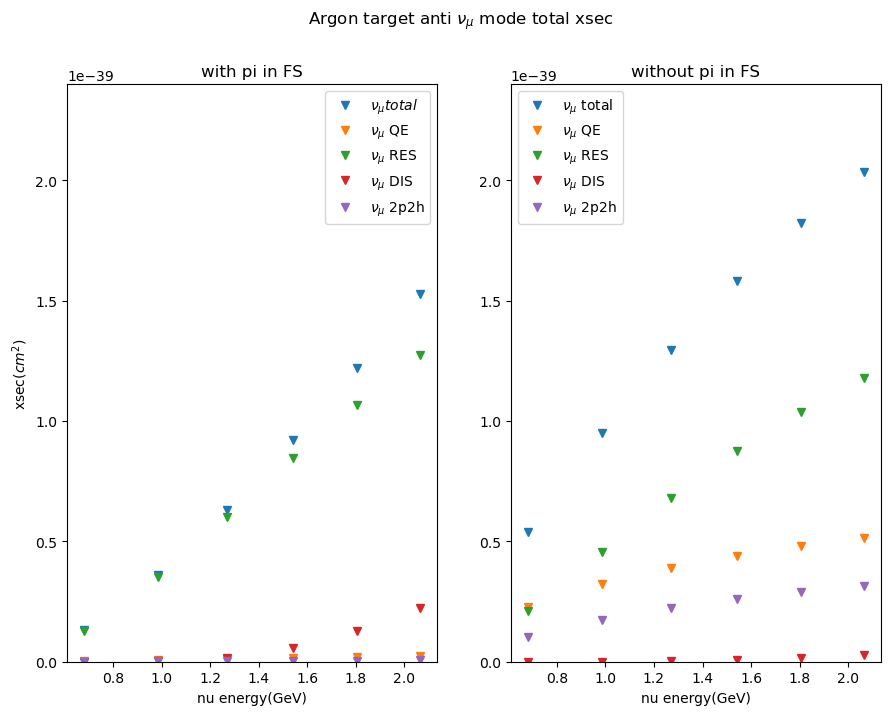

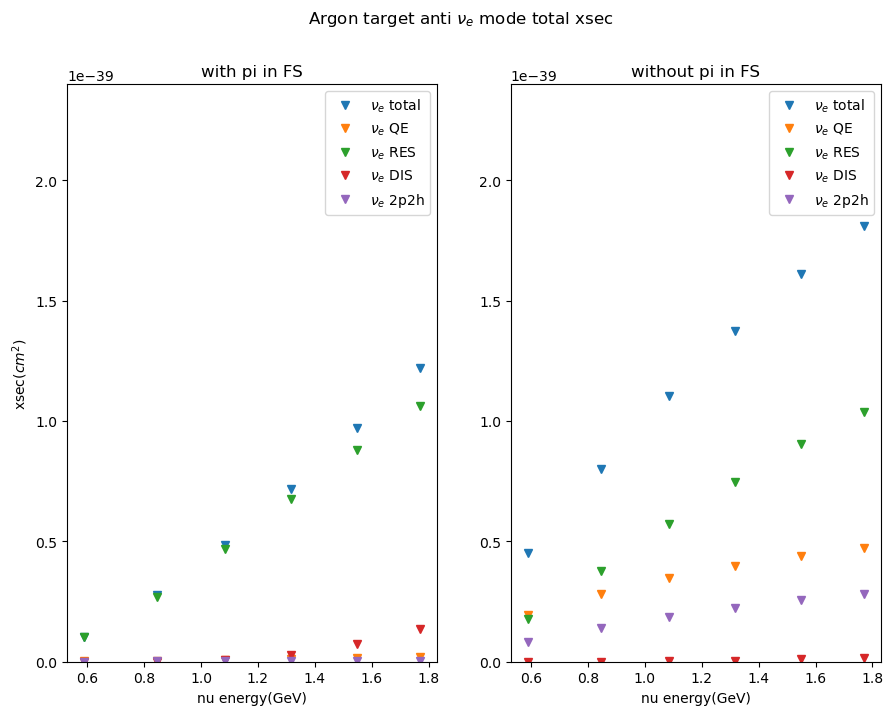

In [39]:
#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Argon target anti ${\\nu}_{\mu}$ mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)


ax1.plot(musig_numu_E_lst, Argon_anti_nu_mu_outana7_xsec_lst+Argon_anti_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu} total$', marker='v')
ax2.plot(musig_numu_E_lst, Argon_anti_nu_mu_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')
#ax3.plot(musig_numu_E_lst, Argon_anti_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')

#QE_xsec


ax1.plot(musig_numu_E_lst, Argon_anti_nu_mu_outana7_QE_xsec_lst+Argon_anti_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
ax2.plot(musig_numu_E_lst, Argon_anti_nu_mu_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
#ax3.plot(musig_numu_E_lst, Argon_anti_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')

#RES_xsec

ax1.plot(musig_numu_E_lst, Argon_anti_nu_mu_outana7_RES_xsec_lst+Argon_anti_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
ax2.plot(musig_numu_E_lst, Argon_anti_nu_mu_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
#ax3.plot(musig_numu_E_lst, Argon_anti_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')

#DIS_xsec

ax1.plot(musig_numu_E_lst, Argon_anti_nu_mu_outana7_DIS_xsec_lst+Argon_anti_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
ax2.plot(musig_numu_E_lst, Argon_anti_nu_mu_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
#ax3.plot(musig_numu_E_lst, Argon_anti_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_numu_E_lst, Argon_anti_nu_mu_outana7_2p2h_xsec_lst+Argon_anti_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
ax2.plot(musig_numu_E_lst, Argon_anti_nu_mu_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
#ax3.plot(musig_numu_E_lst, Argon_anti_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')


ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
ax1.set_ylim(0,2.4e-39)
ax2.legend()
ax2.set_ylim(0,2.4e-39)


plt.show()


#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Argon target anti ${\\nu}_{e}$ mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)
ax1.plot(musig_nue_E_lst, Argon_anti_nu_e_outana7_xsec_lst+Argon_anti_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
ax2.plot(musig_nue_E_lst, Argon_anti_nu_e_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
#ax3.plot(musig_nue_E_lst, Argon_anti_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')

#QE_xsec

ax1.plot(musig_nue_E_lst, Argon_anti_nu_e_outana7_QE_xsec_lst+Argon_anti_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax2.plot(musig_nue_E_lst, Argon_anti_nu_e_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#ax3.plot(musig_nue_E_lst, Argon_anti_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#RES_xsec

ax1.plot(musig_nue_E_lst, Argon_anti_nu_e_outana7_RES_xsec_lst+Argon_anti_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax2.plot(musig_nue_E_lst, Argon_anti_nu_e_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#ax3.plot(musig_nue_E_lst, Argon_anti_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#DIS_xsec

ax1.plot(musig_nue_E_lst, Argon_anti_nu_e_outana7_DIS_xsec_lst+Argon_anti_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax2.plot(musig_nue_E_lst, Argon_anti_nu_e_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
#ax3.plot(musig_nue_E_lst, Argon_anti_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_nue_E_lst, Argon_anti_nu_e_outana7_2p2h_xsec_lst+Argon_anti_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax2.plot(musig_nue_E_lst, Argon_anti_nu_e_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
#ax3.plot(musig_nue_E_lst, Argon_anti_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')

ax1.plot(musig_nue_E_lst, zero_line, linestyle='None')
ax2.plot(musig_nue_E_lst, zero_line, linestyle='None')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
ax1.set_ylim(0,2.4e-39)
ax2.legend()
ax2.set_ylim(0,2.4e-39)


plt.show()